In [85]:
#1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the two standard datasets used for regression and classification
from sklearn.datasets import load_diabetes, load_breast_cancer

# Tools required for splitting data and hyperparameter search
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

# Used for low variance filtering and forward/backward feature selection
from sklearn.feature_selection import (
    VarianceThreshold,
    SequentialFeatureSelector
)

# Used to scale the features before applying selection and models
from sklearn.preprocessing import StandardScaler

# Used to reduce the number of variables into latent factors
from sklearn.decomposition import FactorAnalysis

# Models used in the two parts of the experiment
from sklearn.linear_model import LinearRegression, LogisticRegression

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Avoid displaying unnecessary warning messages
import warnings
warnings.filterwarnings("ignore")

In [86]:
#2
 #Load the standard Diabetes dataset for the regression task
diabetes = load_diabetes()

# Store the input features in a DataFrame
X_reg = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

# Store the continuous target separately
y_reg = pd.Series(
    diabetes.target,
    name="DiseaseProgression"
)

# Combine features and target for easier dataset exploration
diabetes_df = X_reg.copy()
diabetes_df["DiseaseProgression"] = y_reg

print("Diabetes Dataset")
print("Shape:", diabetes_df.shape)
print("Number of features:", X_reg.shape[1])
print("Features:", X_reg.columns.tolist())

Diabetes Dataset
Shape: (442, 11)
Number of features: 10
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [87]:
#3- Load the standard Breast Cancer dataset for classification
cancer = load_breast_cancer()

# Store the 30 input features in a DataFrame
X_cls = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Store the binary target values
y_cls = pd.Series(
    cancer.target,
    name="Target"
)

# Combine the features and target for exploration
cancer_df = X_cls.copy()
cancer_df["Target"] = y_cls

print("Breast Cancer Dataset")
print("Shape:", cancer_df.shape)
print("Number of features:", X_cls.shape[1])
print("Target classes:", cancer.target_names)

Breast Cancer Dataset
Shape: (569, 31)
Number of features: 30
Target classes: ['malignant' 'benign']


In [88]:
#4
#print("DIABETES DATASET")

# Display the first few records to understand the data
display(diabetes_df.head())

# Check the basic dimensions of the dataset
print("Shape:", diabetes_df.shape)

# View statistical information about the numerical features
display(diabetes_df.describe())


print("\n" + "=" * 60)
print("BREAST CANCER DATASET")

# Display the first few records of the classification dataset
display(cancer_df.head())

# Check the dimensions of the dataset
print("Shape:", cancer_df.shape)

# View the statistical summary of the features
display(cancer_df.describe())

DIABETES DATASET


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,DiseaseProgression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,DiseaseProgression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



BREAST CANCER DATASET


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [89]:
#5
#print("DIABETES DATASET")

# Check whether any values are missing
print("Missing values:", diabetes_df.isnull().sum().sum())

# Check for duplicate records
print("Duplicate rows:", diabetes_df.duplicated().sum())


print("\nBREAST CANCER DATASET")

# Check for missing values in the classification dataset
print("Missing values:", cancer_df.isnull().sum().sum())

# Check for duplicate records
print("Duplicate rows:", cancer_df.duplicated().sum())

DIABETES DATASET
Missing values: 0
Duplicate rows: 0

BREAST CANCER DATASET
Missing values: 0
Duplicate rows: 0


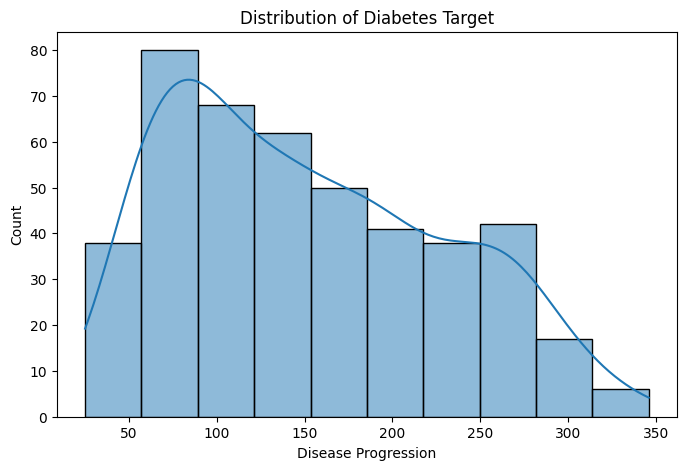

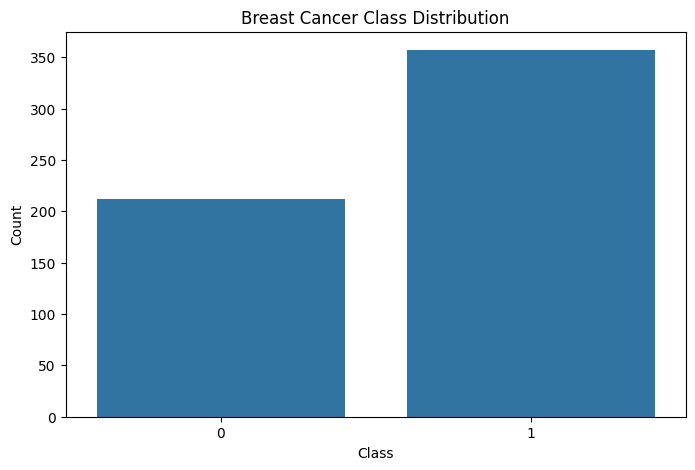

In [90]:
#6
# View the distribution of the continuous regression target
plt.figure(figsize=(8, 5))
sns.histplot(y_reg, kde=True)

plt.title("Distribution of Diabetes Target")
plt.xlabel("Disease Progression")
plt.ylabel("Count")
plt.show()


# Check the number of samples in each classification class
plt.figure(figsize=(8, 5))
sns.countplot(x=y_cls)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [91]:
#7
# Split the regression data into 80% training and 20% testing
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Split the classification data while keeping the class proportions similar
X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=42,
    stratify=y_cls
)

print("Regression training set:", X_reg_train.shape)
print("Regression testing set:", X_reg_test.shape)

print("Classification training set:", X_cls_train.shape)
print("Classification testing set:", X_cls_test.shape)

Regression training set: (353, 10)
Regression testing set: (89, 10)
Classification training set: (455, 30)
Classification testing set: (114, 30)


In [92]:
#8
# Create a scaler for the regression features
reg_scaler = StandardScaler()

# Learn the scaling values from training data and transform it
X_reg_train_scaled = pd.DataFrame(
    reg_scaler.fit_transform(X_reg_train),
    columns=X_reg_train.columns,
    index=X_reg_train.index
)

# Apply the same scaling to the test data
X_reg_test_scaled = pd.DataFrame(
    reg_scaler.transform(X_reg_test),
    columns=X_reg_test.columns,
    index=X_reg_test.index
)


# Create a separate scaler for classification
cls_scaler = StandardScaler()

# Scale the classification training data
X_cls_train_scaled = pd.DataFrame(
    cls_scaler.fit_transform(X_cls_train),
    columns=X_cls_train.columns,
    index=X_cls_train.index
)

# Apply the training-data scaling to the test set
X_cls_test_scaled = pd.DataFrame(
    cls_scaler.transform(X_cls_test),
    columns=X_cls_test.columns,
    index=X_cls_test.index
)

print("Feature scaling completed.")

Feature scaling completed.


In [93]:
#9
# Remove features with very little variation in the regression dataset
reg_variance_filter = VarianceThreshold(threshold=0.01)

# Fit the filter only on the training data
reg_variance_filter.fit(X_reg_train_scaled)

# Get the names of the features that passed the filter
reg_variance_features = X_reg_train_scaled.columns[
    reg_variance_filter.get_support()
].tolist()


# Apply the same process to the classification dataset
cls_variance_filter = VarianceThreshold(threshold=0.01)

cls_variance_filter.fit(X_cls_train_scaled)

cls_variance_features = X_cls_train_scaled.columns[
    cls_variance_filter.get_support()
].tolist()


print("Regression features retained:")
print(reg_variance_features)

print("\nClassification features retained:")
print(cls_variance_features)

Regression features retained:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Classification features retained:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [94]:
#10
def high_correlation_filter(data, threshold=0.90):

    # Calculate the absolute correlation between all features
    correlation_matrix = data.corr().abs()

    # Keep only the upper half of the correlation matrix
    upper_triangle = correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )

    # Find features that are highly correlated with another feature
    columns_to_remove = [
        column
        for column in upper_triangle.columns
        if any(upper_triangle[column] > threshold)
    ]

    # Return the features that are not removed
    return [
        column
        for column in data.columns
        if column not in columns_to_remove
    ]


# Apply the correlation filter to the regression data
reg_correlation_features = high_correlation_filter(
    X_reg_train_scaled
)

# Apply the same filter to the classification data
cls_correlation_features = high_correlation_filter(
    X_cls_train_scaled
)

print("Regression features retained:")
print(reg_correlation_features)

print("\nClassification features retained:")
print(cls_correlation_features)

Regression features retained:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Classification features retained:
['mean radius', 'mean texture', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst symmetry', 'worst fractal dimension']


In [95]:
#11
# Reduce the regression features into five underlying factors
reg_factor_analysis = FactorAnalysis(
    n_components=5,
    random_state=42
)

# Learn the factors from the training data
reg_factor_analysis.fit(X_reg_train_scaled)

# Transform both training and testing data using the learned factors
X_reg_train_factor = reg_factor_analysis.transform(
    X_reg_train_scaled
)

X_reg_test_factor = reg_factor_analysis.transform(
    X_reg_test_scaled
)


# Reduce the 30 classification features into ten factors
cls_factor_analysis = FactorAnalysis(
    n_components=10,
    random_state=42
)

# Learn the factors from the classification training data
cls_factor_analysis.fit(X_cls_train_scaled)

# Transform the classification datasets
X_cls_train_factor = cls_factor_analysis.transform(
    X_cls_train_scaled
)

X_cls_test_factor = cls_factor_analysis.transform(
    X_cls_test_scaled
)

print("Regression:")
print("Original features:", X_reg.shape[1])
print("Reduced factors:", X_reg_train_factor.shape[1])

print("\nClassification:")
print("Original features:", X_cls.shape[1])
print("Reduced factors:", X_cls_train_factor.shape[1])

Regression:
Original features: 10
Reduced factors: 5

Classification:
Original features: 30
Reduced factors: 10


In [96]:
#12
# Use Linear Regression to decide which regression features are useful
forward_reg_model = LinearRegression()

# Add features one by one and keep the combination giving better CV performance
forward_reg = SequentialFeatureSelector(
    forward_reg_model,
    n_features_to_select=5,
    direction="forward",
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

forward_reg.fit(
    X_reg_train_scaled,
    y_reg_train
)

# Store the names of the selected regression features
reg_forward_features = X_reg_train_scaled.columns[
    forward_reg.get_support()
].tolist()


# Use Logistic Regression for forward selection in classification
forward_cls_model = LogisticRegression(
    max_iter=5000
)

forward_cls = SequentialFeatureSelector(
    forward_cls_model,
    n_features_to_select=10,
    direction="forward",
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

forward_cls.fit(
    X_cls_train_scaled,
    y_cls_train
)

# Store the selected classification features
cls_forward_features = X_cls_train_scaled.columns[
    forward_cls.get_support()
].tolist()


print("Regression Forward Selection:")
print(reg_forward_features)

print("\nClassification Forward Selection:")
print(cls_forward_features)

Regression Forward Selection:
['sex', 'bmi', 'bp', 's3', 's5']

Classification Forward Selection:
['mean texture', 'mean area', 'mean smoothness', 'mean concavity', 'mean symmetry', 'symmetry error', 'worst radius', 'worst perimeter', 'worst area', 'worst smoothness']


In [97]:
#13
# Start with all regression features and remove less useful ones
backward_reg_model = LinearRegression()

backward_reg = SequentialFeatureSelector(
    backward_reg_model,
    n_features_to_select=5,
    direction="backward",
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

backward_reg.fit(
    X_reg_train_scaled,
    y_reg_train
)

# Store the remaining regression features
reg_backward_features = X_reg_train_scaled.columns[
    backward_reg.get_support()
].tolist()


# Start with all classification features and remove weaker features
backward_cls_model = LogisticRegression(
    max_iter=5000
)

backward_cls = SequentialFeatureSelector(
    backward_cls_model,
    n_features_to_select=10,
    direction="backward",
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

backward_cls.fit(
    X_cls_train_scaled,
    y_cls_train
)

# Store the remaining classification features
cls_backward_features = X_cls_train_scaled.columns[
    backward_cls.get_support()
].tolist()


print("Regression Backward Elimination:")
print(reg_backward_features)

print("\nClassification Backward Elimination:")
print(cls_backward_features)

Regression Backward Elimination:
['sex', 'bmi', 'bp', 's1', 's5']

Classification Backward Elimination:
['mean texture', 'texture error', 'perimeter error', 'worst radius', 'worst texture', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [98]:
#14
# Keep all selected feature names together for easy comparison
reg_feature_summary = {
    "Original": X_reg.columns.tolist(),
    "Low Variance": reg_variance_features,
    "High Correlation": reg_correlation_features,
    "Forward Selection": reg_forward_features,
    "Backward Elimination": reg_backward_features
}

cls_feature_summary = {
    "Original": X_cls.columns.tolist(),
    "Low Variance": cls_variance_features,
    "High Correlation": cls_correlation_features,
    "Forward Selection": cls_forward_features,
    "Backward Elimination": cls_backward_features
}


print("REGRESSION FEATURE COUNTS")

for method, features in reg_feature_summary.items():
    print(method, ":", len(features))


print("\nCLASSIFICATION FEATURE COUNTS")

for method, features in cls_feature_summary.items():
    print(method, ":", len(features))

REGRESSION FEATURE COUNTS
Original : 10
Low Variance : 10
High Correlation : 10
Forward Selection : 5
Backward Elimination : 5

CLASSIFICATION FEATURE COUNTS
Original : 30
Low Variance : 30
High Correlation : 20
Forward Selection : 10
Backward Elimination : 10


In [99]:
#15
# Apply the low variance filter to the original training data
# This makes the variance values meaningful before standardization
reg_variance_filter = VarianceThreshold(threshold=0.001)

reg_variance_filter.fit(X_reg_train)

# Get the regression features that passed the variance filter
reg_variance_features = X_reg_train.columns[
    reg_variance_filter.get_support()
].tolist()


# Apply the same filter to the classification training data
cls_variance_filter = VarianceThreshold(threshold=0.01)

cls_variance_filter.fit(X_cls_train)

# Get the classification features that passed the variance filter
cls_variance_features = X_cls_train.columns[
    cls_variance_filter.get_support()
].tolist()


print("Regression features after Low Variance Filter:")
print(reg_variance_features)

print("\nClassification features after Low Variance Filter:")
print(cls_variance_features)

Regression features after Low Variance Filter:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Classification features after Low Variance Filter:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'radius error', 'texture error', 'perimeter error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst compactness', 'worst concavity']


In [100]:
#16- Store the feature names selected by each regression technique
reg_selected_sets = {
    "Original": X_reg_train_scaled.columns.tolist(),
    "Low Variance": reg_variance_features,
    "High Correlation": reg_correlation_features,
    "Forward Selection": reg_forward_features,
    "Backward Elimination": reg_backward_features
}


# Store the feature names selected by each classification technique
cls_selected_sets = {
    "Original": X_cls_train_scaled.columns.tolist(),
    "Low Variance": cls_variance_features,
    "High Correlation": cls_correlation_features,
    "Forward Selection": cls_forward_features,
    "Backward Elimination": cls_backward_features
}


print("Regression feature sets created:")
for method, features in reg_selected_sets.items():
    print(method, ":", len(features), "features")


print("\nClassification feature sets created:")
for method, features in cls_selected_sets.items():
    print(method, ":", len(features), "features")

Regression feature sets created:
Original : 10 features
Low Variance : 10 features
High Correlation : 10 features
Forward Selection : 5 features
Backward Elimination : 5 features

Classification feature sets created:
Original : 30 features
Low Variance : 14 features
High Correlation : 20 features
Forward Selection : 10 features
Backward Elimination : 10 features


In [101]:
# 17-Store the trained regression models
regression_models = {}

# Store the predictions for later evaluation
regression_predictions = {}


# Train one Linear Regression model for each feature-selection method
for method, features in reg_selected_sets.items():

    # Select the required training columns
    X_train_selected = X_reg_train_scaled[features]

    # Select the same columns from the test data
    X_test_selected = X_reg_test_scaled[features]

    # Create the Linear Regression model
    model = LinearRegression()

    # Train the model using the selected features
    model.fit(
        X_train_selected,
        y_reg_train
    )

    # Predict the target values for the test set
    predictions = model.predict(
        X_test_selected
    )

    # Save the trained model
    regression_models[method] = model

    # Save the predictions
    regression_predictions[method] = predictions


print("Linear Regression models trained successfully.")

for method in regression_models:
    print(method, ":", len(reg_selected_sets[method]), "features")

Linear Regression models trained successfully.
Original : 10 features
Low Variance : 10 features
High Correlation : 10 features
Forward Selection : 5 features
Backward Elimination : 5 features


In [102]:
#18- Store regression evaluation results
regression_results = []


# Evaluate every Linear Regression model
for method, predictions in regression_predictions.items():

    # Calculate Mean Absolute Error
    mae = mean_absolute_error(
        y_reg_test,
        predictions
    )

    # Calculate Mean Squared Error
    mse = mean_squared_error(
        y_reg_test,
        predictions
    )

    # Calculate Root Mean Squared Error
    rmse = np.sqrt(mse)

    # Calculate R-squared score
    r2 = r2_score(
        y_reg_test,
        predictions
    )

    # Store the results
    regression_results.append({
        "Method": method,
        "Features": len(reg_selected_sets[method]),
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })


# Convert the results into a DataFrame
regression_results_df = pd.DataFrame(
    regression_results
)

print("Linear Regression Test Results")
display(regression_results_df.sort_values(
    "R2",
    ascending=False
))

Linear Regression Test Results


,Method,Features,MAE,MSE,RMSE,R2
3,Forward Selection,5,42.809313,2811.385100,53.022496,0.469365
4,Backward Elimination,5,43.262847,2855.149116,53.433595,0.461105
0,Original,10,42.794095,2900.193628,53.853446,0.452603
2,High Correlation,10,42.794095,2900.193628,53.853446,0.452603
1,Low Variance,10,42.794095,2900.193628,53.853446,0.452603


In [103]:
#19- Store the trained classification models
classification_models = {}

# Store predictions for later evaluation
classification_predictions = {}


# Train one Logistic Regression model for every feature-selection method
for method, features in cls_selected_sets.items():

    # Select the required training features
    X_train_selected = X_cls_train_scaled[features]

    # Select the same features from the test data
    X_test_selected = X_cls_test_scaled[features]

    # Create the Logistic Regression model
    model = LogisticRegression(
        max_iter=5000
    )

    # Train the classification model
    model.fit(
        X_train_selected,
        y_cls_train
    )

    # Predict the test classes
    predictions = model.predict(
        X_test_selected
    )

    # Save the trained model
    classification_models[method] = model

    # Save the predictions
    classification_predictions[method] = predictions


print("Logistic Regression models trained successfully.")

for method in classification_models:
    print(method, ":", len(cls_selected_sets[method]), "features")

Logistic Regression models trained successfully.
Original : 30 features
Low Variance : 14 features
High Correlation : 20 features
Forward Selection : 10 features
Backward Elimination : 10 features


In [104]:
#20-
# FACTOR ANALYSIS MODEL EVALUATION



# Linear Regression - Factor Analysis

# Train Linear Regression using the factor-transformed data
reg_factor_model = LinearRegression()

reg_factor_model.fit(
    X_reg_train_factor,
    y_reg_train
)

# Predict the test data
reg_factor_predictions = reg_factor_model.predict(
    X_reg_test_factor
)

# Calculate regression metrics
reg_factor_mae = mean_absolute_error(
    y_reg_test,
    reg_factor_predictions
)

reg_factor_mse = mean_squared_error(
    y_reg_test,
    reg_factor_predictions
)

reg_factor_rmse = np.sqrt(
    reg_factor_mse
)

reg_factor_r2 = r2_score(
    y_reg_test,
    reg_factor_predictions
)

# Add Factor Analysis to the regression results
regression_results_df = pd.concat(
    [
        regression_results_df,
        pd.DataFrame([
            {
                "Method": "Factor Analysis",
                "Features": X_reg_train_factor.shape[1],
                "MAE": reg_factor_mae,
                "MSE": reg_factor_mse,
                "RMSE": reg_factor_rmse,
                "R2": reg_factor_r2
            }
        ])
    ],
    ignore_index=True
)



# Logistic Regression - Factor Analysis


# Train Logistic Regression using factor-transformed data
cls_factor_model = LogisticRegression(
    max_iter=5000
)

cls_factor_model.fit(
    X_cls_train_factor,
    y_cls_train
)

# Predict the test data
cls_factor_predictions = cls_factor_model.predict(
    X_cls_test_factor
)

# Calculate classification metrics
cls_factor_accuracy = accuracy_score(
    y_cls_test,
    cls_factor_predictions
)

cls_factor_precision = precision_score(
    y_cls_test,
    cls_factor_predictions
)

cls_factor_recall = recall_score(
    y_cls_test,
    cls_factor_predictions
)

cls_factor_f1 = f1_score(
    y_cls_test,
    cls_factor_predictions
)

# Add Factor Analysis to classification results
classification_results_df = pd.concat(
    [
        classification_results_df,
        pd.DataFrame([
            {
                "Method": "Factor Analysis",
                "Features": X_cls_train_factor.shape[1],
                "Accuracy": cls_factor_accuracy,
                "Precision": cls_factor_precision,
                "Recall": cls_factor_recall,
                "F1 Score": cls_factor_f1
            }
        ])
    ],
    ignore_index=True
)


print("Factor Analysis models evaluated successfully.")

print("\nFactor Analysis Regression Results")
display(
    regression_results_df[
        regression_results_df["Method"] == "Factor Analysis"
    ]
)

print("\nFactor Analysis Classification Results")
display(
    classification_results_df[
        classification_results_df["Method"] == "Factor Analysis"
    ]
)

Factor Analysis models evaluated successfully.

Factor Analysis Regression Results


,Method,Features,MAE,MSE,RMSE,R2
5,Factor Analysis,5,42.835049,2880.874538,53.673779,0.456249



Factor Analysis Classification Results


,Method,Features,Accuracy,Precision,Recall,F1 Score
5,Factor Analysis,10,0.973684,0.96,1.0,0.979592


In [105]:
#21- Store classification evaluation results
classification_results = []


# Evaluate every Logistic Regression model
for method, predictions in classification_predictions.items():

    # Calculate classification metrics
    accuracy = accuracy_score(
        y_cls_test,
        predictions
    )

    precision = precision_score(
        y_cls_test,
        predictions
    )

    recall = recall_score(
        y_cls_test,
        predictions
    )

    f1 = f1_score(
        y_cls_test,
        predictions
    )

    # Store the results
    classification_results.append({
        "Method": method,
        "Features": len(cls_selected_sets[method]),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })


# Convert the results into a DataFrame
classification_results_df = pd.DataFrame(
    classification_results
)

print("Logistic Regression Test Results")
display(classification_results_df.sort_values(
    "Accuracy",
    ascending=False
))

Logistic Regression Test Results


,Method,Features,Accuracy,Precision,Recall,F1 Score
0,Original,30,0.982456,0.986111,0.986111,0.986111
2,High Correlation,20,0.982456,0.986111,0.986111,0.986111
4,Backward Elimination,10,0.973684,0.985915,0.972222,0.979021
1,Low Variance,14,0.956140,0.946667,0.986111,0.965986
3,Forward Selection,10,0.938596,0.971014,0.930556,0.950355


In [106]:
# 22-
# FACTOR ANALYSIS CROSS-VALIDATION


# Regression Factor Analysis CV
reg_factor_cv_scores = cross_val_score(
    LinearRegression(),
    X_reg_train_factor,
    y_reg_train,
    cv=5,
    scoring="r2"
)

reg_factor_cv_result = pd.DataFrame([
    {
        "Method": "Factor Analysis",
        "Features": X_reg_train_factor.shape[1],
        "CV Mean R2": reg_factor_cv_scores.mean(),
        "CV Std": reg_factor_cv_scores.std()
    }
])

# Add Factor Analysis to regression CV results
reg_cv_results_df = pd.concat(
    [
        reg_cv_results_df,
        reg_factor_cv_result
    ],
    ignore_index=True
)


# -----------------------------
# Classification Factor Analysis CV
# -----------------------------

cls_factor_cv_scores = cross_val_score(
    LogisticRegression(max_iter=5000),
    X_cls_train_factor,
    y_cls_train,
    cv=5,
    scoring="accuracy"
)

cls_factor_cv_result = pd.DataFrame([
    {
        "Method": "Factor Analysis",
        "Features": X_cls_train_factor.shape[1],
        "CV Mean Accuracy": cls_factor_cv_scores.mean(),
        "CV Std": cls_factor_cv_scores.std()
    }
])

# Add Factor Analysis to classification CV results
cls_cv_results_df = pd.concat(
    [
        cls_cv_results_df,
        cls_factor_cv_result
    ],
    ignore_index=True
)


print("Factor Analysis Cross-Validation Results")

print("\nRegression")
display(
    reg_factor_cv_result
)

print("\nClassification")
display(
    cls_factor_cv_result
)

Factor Analysis Cross-Validation Results

Regression


,Method,Features,CV Mean R2,CV Std
0,Factor Analysis,5,0.456847,0.128479



Classification


,Method,Features,CV Mean Accuracy,CV Std
0,Factor Analysis,10,0.973626,0.020382


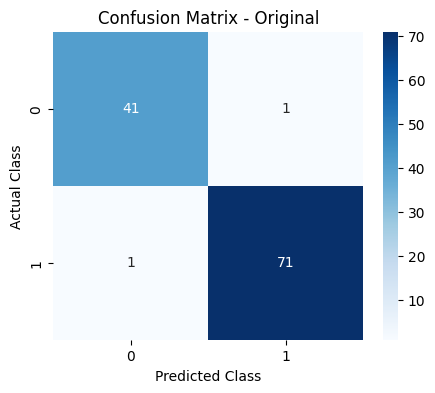

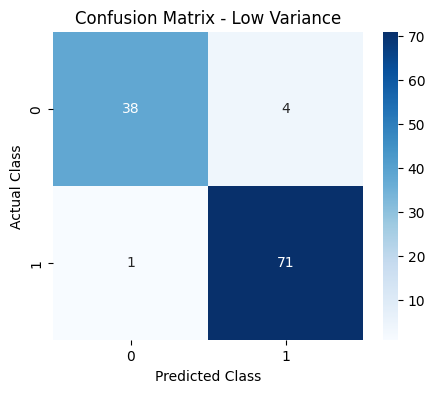

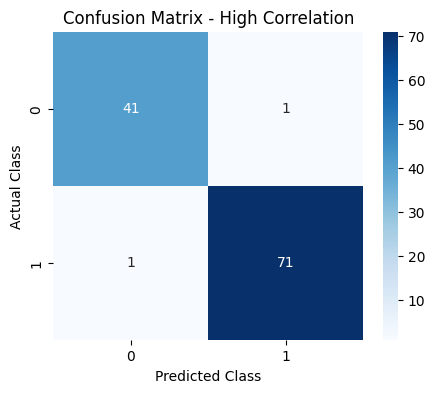

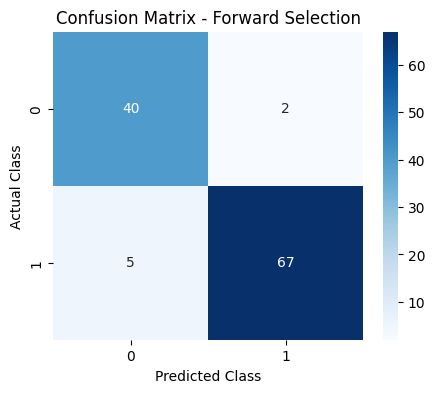

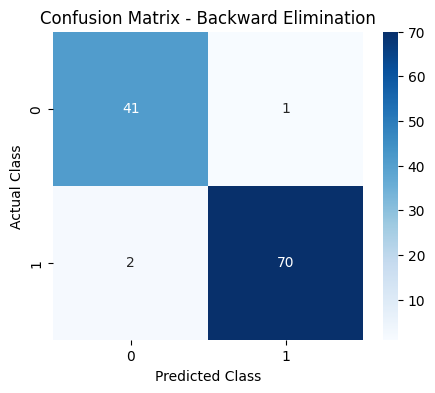

In [107]:
# 23-Display confusion matrices for each feature-selection method
for method, predictions in classification_predictions.items():

    # Calculate the confusion matrix
    cm = confusion_matrix(
        y_cls_test,
        predictions
    )

    # Create the heatmap
    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(
        "Confusion Matrix - " + method
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.show()

In [108]:
#24-
from sklearn.model_selection import cross_val_score


# Store cross-validation results
reg_cv_results = []


# Evaluate each regression feature set using 5-fold CV
for method, features in reg_selected_sets.items():

    # Select the required features
    X_selected = X_reg_train_scaled[features]

    # Create a fresh Linear Regression model
    model = LinearRegression()

    # Perform 5-fold cross-validation using R2
    scores = cross_val_score(
        model,
        X_selected,
        y_reg_train,
        cv=5,
        scoring="r2"
    )

    # Store the mean and standard deviation
    reg_cv_results.append({
        "Method": method,
        "Features": len(features),
        "CV Mean R2": scores.mean(),
        "CV Std": scores.std()
    })


# Convert the results into a DataFrame
reg_cv_results_df = pd.DataFrame(
    reg_cv_results
)

print("Linear Regression 5-Fold Cross-Validation")
display(reg_cv_results_df.sort_values(
    "CV Mean R2",
    ascending=False
))

Linear Regression 5-Fold Cross-Validation


,Method,Features,CV Mean R2,CV Std
3,Forward Selection,5,0.463556,0.127068
4,Backward Elimination,5,0.453939,0.113040
0,Original,10,0.449256,0.144095
2,High Correlation,10,0.449256,0.144095
1,Low Variance,10,0.449256,0.144095


In [109]:
# 25-Store classification cross-validation results
cls_cv_results = []


# Evaluate each classification feature set using 5-fold CV
for method, features in cls_selected_sets.items():

    # Select the required features
    X_selected = X_cls_train_scaled[features]

    # Create a fresh Logistic Regression model
    model = LogisticRegression(
        max_iter=5000
    )

    # Perform 5-fold cross-validation
    scores = cross_val_score(
        model,
        X_selected,
        y_cls_train,
        cv=5,
        scoring="accuracy"
    )

    # Store the mean and standard deviation
    cls_cv_results.append({
        "Method": method,
        "Features": len(features),
        "CV Mean Accuracy": scores.mean(),
        "CV Std": scores.std()
    })


# Convert the results into a DataFrame
cls_cv_results_df = pd.DataFrame(
    cls_cv_results
)

print("Logistic Regression 5-Fold Cross-Validation")
display(cls_cv_results_df.sort_values(
    "CV Mean Accuracy",
    ascending=False
))

Logistic Regression 5-Fold Cross-Validation


,Method,Features,CV Mean Accuracy,CV Std
3,Forward Selection,10,0.986813,0.010767
4,Backward Elimination,10,0.984615,0.011207
0,Original,30,0.980220,0.012815
2,High Correlation,20,0.971429,0.020382
1,Low Variance,14,0.960440,0.011207


In [110]:
#26- Implement Linear Regression using Gradient Descent
def linear_gradient_descent(X, y, learning_rate=0.01, iterations=1000):

    # Convert the data into NumPy arrays for mathematical operations
    X_array = np.asarray(X)
    y_array = np.asarray(y)

    # Add a column of ones for the intercept term
    X_with_bias = np.c_[
        np.ones(X_array.shape[0]),
        X_array
    ]

    # Start all model parameters with zero values
    weights = np.zeros(
        X_with_bias.shape[1]
    )

    # Store the loss value after every iteration
    loss_history = []

    # Perform gradient descent repeatedly
    for i in range(iterations):

        # Calculate the current predictions
        predictions = X_with_bias @ weights

        # Calculate the prediction error
        error = predictions - y_array

        # Calculate the gradient of the Mean Squared Error
        gradient = (
            2 / len(y_array)
        ) * (
            X_with_bias.T @ error
        )

        # Update the model parameters
        weights = weights - (
            learning_rate * gradient
        )

        # Calculate and store the current MSE
        loss = np.mean(error ** 2)
        loss_history.append(loss)

    # Return the final weights and loss history
    return weights, loss_history

In [111]:
#27
# LOGISTIC REGRESSION USING GRADIENT DESCENT


def sigmoid(z):

    # Convert the input into probabilities between 0 and 1
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def logistic_gradient_descent(
    X,
    y,
    learning_rate=0.01,
    iterations=1000
):

    # Convert input data into NumPy arrays
    X_array = np.asarray(X)
    y_array = np.asarray(y)

    # Add a column of ones for the intercept
    X_with_bias = np.c_[
        np.ones(X_array.shape[0]),
        X_array
    ]

    # Initialize weights with zeros
    weights = np.zeros(
        X_with_bias.shape[1]
    )

    # Store loss values
    loss_history = []

    # Perform gradient descent
    for i in range(iterations):

        # Calculate linear output
        linear_output = X_with_bias @ weights

        # Convert to probability
        probabilities = sigmoid(
            linear_output
        )

        # Calculate error
        error = probabilities - y_array

        # Calculate gradient
        gradient = (
            X_with_bias.T @ error
        ) / len(y_array)

        # Update weights
        weights = weights - (
            learning_rate * gradient
        )

        # Calculate binary cross-entropy loss
        probabilities_safe = np.clip(
            probabilities,
            1e-10,
            1 - 1e-10
        )

        loss = -np.mean(
            y_array * np.log(probabilities_safe)
            +
            (1 - y_array)
            * np.log(1 - probabilities_safe)
        )

        loss_history.append(loss)

    return weights, loss_history

In [112]:

#28- LOGISTIC GRADIENT DESCENT - LEARNING RATE EXPERIMENT


# Use the Forward Selection features
logistic_gd_features = cls_forward_features

X_logistic_gd_train = X_cls_train_scaled[
    logistic_gd_features
]

X_logistic_gd_test = X_cls_test_scaled[
    logistic_gd_features
]


# Test different learning rates
logistic_learning_rates = [
    0.001,
    0.005,
    0.01,
    0.05
]


logistic_learning_rate_results = {}


# Run Gradient Descent for each learning rate
for lr in logistic_learning_rates:

    weights, loss_history = logistic_gradient_descent(
        X_logistic_gd_train,
        y_cls_train,
        learning_rate=lr,
        iterations=1000
    )

    logistic_learning_rate_results[lr] = loss_history


print("Logistic Regression learning-rate experiment completed.")

for lr, losses in logistic_learning_rate_results.items():

    print(
        "Learning Rate:",
        lr,
        "| Final Log Loss:",
        round(losses[-1], 6)
    )

Logistic Regression learning-rate experiment completed.
Learning Rate: 0.001 | Final Log Loss: 0.350999
Learning Rate: 0.005 | Final Log Loss: 0.176809
Learning Rate: 0.01 | Final Log Loss: 0.137035
Learning Rate: 0.05 | Final Log Loss: 0.09045


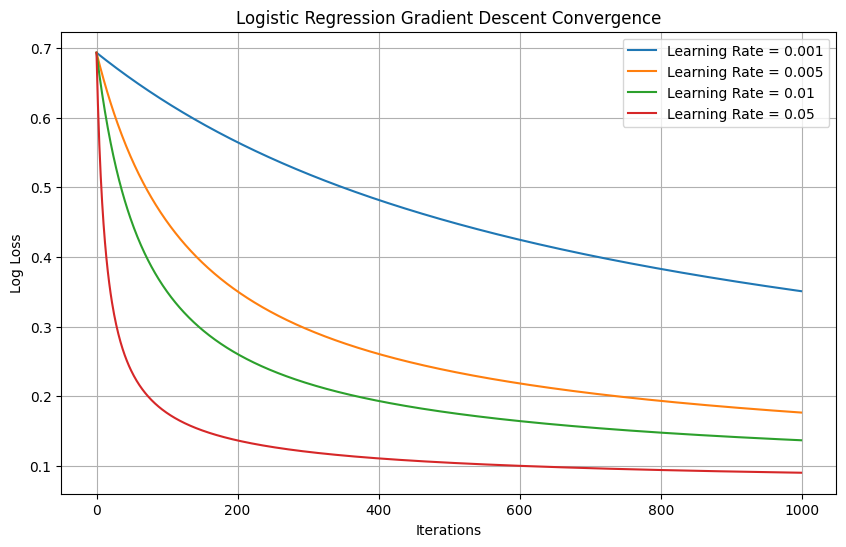

In [113]:
#29
# LOGISTIC GRADIENT DESCENT CONVERGENCE


plt.figure(figsize=(10, 6))

for lr, losses in logistic_learning_rate_results.items():

    plt.plot(
        losses,
        label=f"Learning Rate = {lr}"
    )


plt.title(
    "Logistic Regression Gradient Descent Convergence"
)

plt.xlabel("Iterations")

plt.ylabel("Log Loss")

plt.legend()

plt.grid(True)

plt.show()

In [114]:
# 30
# LOGISTIC GRADIENT DESCENT - ITERATION EXPERIMENT


# Select a suitable learning rate
logistic_selected_learning_rate = 0.01


# Test different iteration counts
logistic_iteration_values = [
    100,
    500,
    1000,
    2000,
    5000
]


logistic_iteration_results = []


for iterations in logistic_iteration_values:

    # Train Gradient Descent
    weights, loss_history = logistic_gradient_descent(
        X_logistic_gd_train,
        y_cls_train,
        learning_rate=logistic_selected_learning_rate,
        iterations=iterations
    )

    # Prepare test data with bias
    X_test_array = np.asarray(
        X_logistic_gd_test
    )

    X_test_bias = np.c_[
        np.ones(X_test_array.shape[0]),
        X_test_array
    ]

    # Calculate probabilities
    test_probabilities = sigmoid(
        X_test_bias @ weights
    )

    # Convert probabilities to classes
    test_predictions = (
        test_probabilities >= 0.5
    ).astype(int)

    # Calculate accuracy
    accuracy = accuracy_score(
        y_cls_test,
        test_predictions
    )

    # Calculate F1 score
    f1 = f1_score(
        y_cls_test,
        test_predictions
    )

    # Store results
    logistic_iteration_results.append({
        "Iterations": iterations,
        "Test Accuracy": accuracy,
        "Test F1 Score": f1,
        "Final Training Log Loss": loss_history[-1]
    })


# Convert results to DataFrame
logistic_iteration_results_df = pd.DataFrame(
    logistic_iteration_results
)


print(
    "Logistic Regression Gradient Descent "
    "Iteration Experiment"
)

display(
    logistic_iteration_results_df
)

Logistic Regression Gradient Descent Iteration Experiment


,Iterations,Test Accuracy,Test F1 Score,Final Training Log Loss
0,100,0.938596,0.951724,0.351730
1,500,0.938596,0.951724,0.176810
2,1000,0.938596,0.951724,0.137035
3,2000,0.947368,0.957746,0.111098
4,5000,0.947368,0.957746,0.090460


In [115]:

# 31-FINAL LOGISTIC REGRESSION GRADIENT DESCENT MODEL


# Train the final model
logistic_gd_weights, logistic_gd_loss_history = (
    logistic_gradient_descent(
        X_logistic_gd_train,
        y_cls_train,
        learning_rate=logistic_selected_learning_rate,
        iterations=5000
    )
)


# Prepare test data
X_test_array = np.asarray(
    X_logistic_gd_test
)

X_test_bias = np.c_[
    np.ones(X_test_array.shape[0]),
    X_test_array
]


# Generate probabilities
logistic_gd_probabilities = sigmoid(
    X_test_bias @ logistic_gd_weights
)


# Convert probabilities to classes
logistic_gd_predictions = (
    logistic_gd_probabilities >= 0.5
).astype(int)


# Calculate final metrics
logistic_gd_accuracy = accuracy_score(
    y_cls_test,
    logistic_gd_predictions
)

logistic_gd_precision = precision_score(
    y_cls_test,
    logistic_gd_predictions
)

logistic_gd_recall = recall_score(
    y_cls_test,
    logistic_gd_predictions
)

logistic_gd_f1 = f1_score(
    y_cls_test,
    logistic_gd_predictions
)


print("Logistic Regression Gradient Descent Results")

print(
    "Accuracy:",
    round(logistic_gd_accuracy, 4)
)

print(
    "Precision:",
    round(logistic_gd_precision, 4)
)

print(
    "Recall:",
    round(logistic_gd_recall, 4)
)

print(
    "F1 Score:",
    round(logistic_gd_f1, 4)
)

Logistic Regression Gradient Descent Results
Accuracy: 0.9474
Precision: 0.9714
Recall: 0.9444
F1 Score: 0.9577


In [116]:
#32- Use the Forward Selection feature set for the experiment
gd_reg_features = reg_forward_features

# Select the training features
X_gd_train = X_reg_train_scaled[
    gd_reg_features
]

# Select the test features
X_gd_test = X_reg_test_scaled[
    gd_reg_features
]


# Try different learning rates
learning_rates = [
    0.0001,
    0.0005,
    0.001,
    0.005
]

# Store the convergence history
learning_rate_results = {}


# Run Gradient Descent for every learning rate
for lr in learning_rates:

    # Train the model using the current learning rate
    weights, loss_history = linear_gradient_descent(
        X_gd_train,
        y_reg_train,
        learning_rate=lr,
        iterations=1000
    )

    # Store the loss history
    learning_rate_results[lr] = loss_history


print("Learning-rate experiment completed.")

for lr, losses in learning_rate_results.items():
    print(
        "Learning Rate:",
        lr,
        "| Final MSE:",
        round(losses[-1], 4)
    )

Learning-rate experiment completed.
Learning Rate: 0.0001 | Final MSE: 20240.2382
Learning Rate: 0.0005 | Final MSE: 6252.7392
Learning Rate: 0.001 | Final MSE: 3392.7428
Learning Rate: 0.005 | Final MSE: 2948.9645


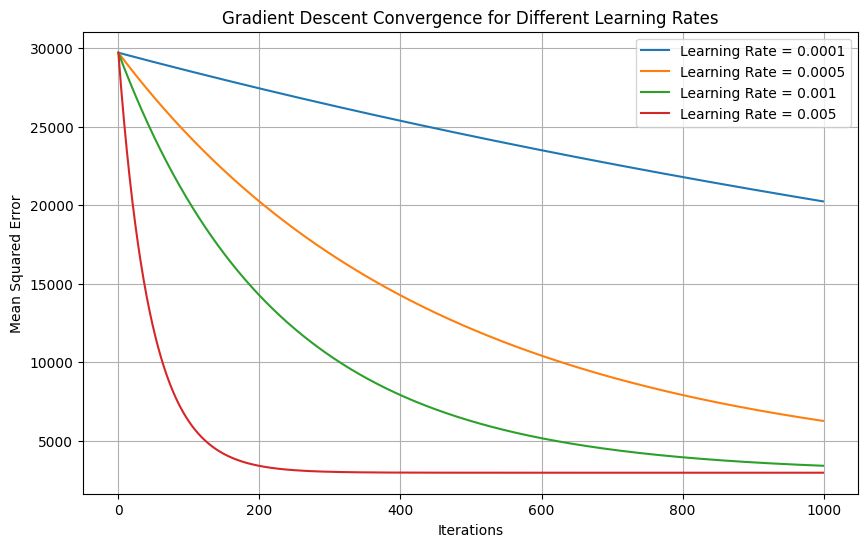

In [117]:
#33- Plot the convergence behaviour for different learning rates
plt.figure(figsize=(10, 6))

for lr, losses in learning_rate_results.items():

    # Plot MSE against the number of iterations
    plt.plot(
        losses,
        label=f"Learning Rate = {lr}"
    )


plt.title(
    "Gradient Descent Convergence for Different Learning Rates"
)

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.grid(True)

plt.show()

In [118]:
#34- Use a suitable learning rate for the iteration experiment
selected_learning_rate = 0.001

# Test different numbers of iterations
iteration_values = [
    100,
    500,
    1000,
    2000,
    5000
]

# Store the final MSE for each iteration count
iteration_results = []


# Train the model using different iteration counts
for iterations in iteration_values:

    # Run Gradient Descent
    weights, loss_history = linear_gradient_descent(
        X_gd_train,
        y_reg_train,
        learning_rate=selected_learning_rate,
        iterations=iterations
    )

    # Make predictions on the test data
    X_test_array = np.asarray(X_gd_test)

    X_test_bias = np.c_[
        np.ones(X_test_array.shape[0]),
        X_test_array
    ]

    predictions = X_test_bias @ weights

    # Calculate test RMSE
    rmse = np.sqrt(
        mean_squared_error(
            y_reg_test,
            predictions
        )
    )

    # Store the result
    iteration_results.append({
        "Iterations": iterations,
        "Test RMSE": rmse,
        "Final Training MSE": loss_history[-1]
    })


# Convert the results to a DataFrame
iteration_results_df = pd.DataFrame(
    iteration_results
)

print("Gradient Descent Iteration Experiment")

display(iteration_results_df)

Gradient Descent Iteration Experiment


,Iterations,Test RMSE,Final Training MSE
0,100,136.170543,20299.618323
1,500,78.418160,6255.997811
2,1000,57.736234,3392.742781
3,2000,53.163199,2957.463531
4,5000,53.017021,2948.964566


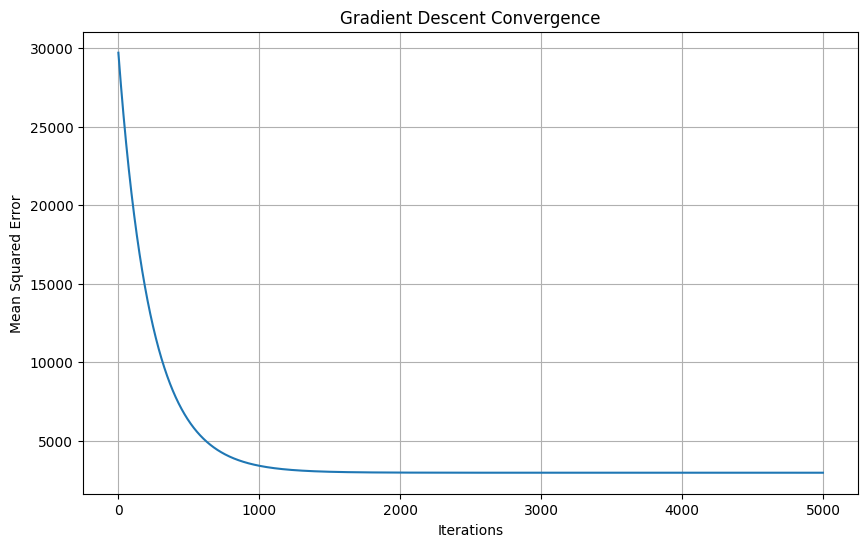

Gradient Descent Results
MAE: 42.8057
RMSE: 53.017
R2 Score: 0.4695


In [119]:
#35-Train the final Gradient Descent model
gd_weights, gd_loss_history = linear_gradient_descent(
    X_gd_train,
    y_reg_train,
    learning_rate=selected_learning_rate,
    iterations=5000
)


# Plot the training loss over iterations
plt.figure(figsize=(10, 6))

plt.plot(
    gd_loss_history
)

plt.title(
    "Gradient Descent Convergence"
)

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")

plt.grid(True)

plt.show()


# Create predictions using the final Gradient Descent model
X_test_array = np.asarray(X_gd_test)

X_test_bias = np.c_[
    np.ones(X_test_array.shape[0]),
    X_test_array
]

gd_predictions = X_test_bias @ gd_weights


# Calculate final Gradient Descent performance
gd_mae = mean_absolute_error(
    y_reg_test,
    gd_predictions
)

gd_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        gd_predictions
    )
)

gd_r2 = r2_score(
    y_reg_test,
    gd_predictions
)


print("Gradient Descent Results")
print("MAE:", round(gd_mae, 4))
print("RMSE:", round(gd_rmse, 4))
print("R2 Score:", round(gd_r2, 4))

In [120]:
#36- Use the Forward Selection features for GridSearch
grid_features = cls_forward_features

# Select the training data using the chosen features
X_grid_train = X_cls_train_scaled[
    grid_features
]

# Select the corresponding test features
X_grid_test = X_cls_test_scaled[
    grid_features
]


# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=5000
)


# Define the hyperparameter values to test
param_grid = {
    "C": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}


# Perform 5-fold GridSearchCV
logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)


# Train and compare all parameter combinations
logistic_grid.fit(
    X_grid_train,
    y_cls_train
)


# Display the best hyperparameter
print(
    "Best C:",
    logistic_grid.best_params_["C"]
)

# Display the best cross-validation score
print(
    "Best CV Accuracy:",
    round(
        logistic_grid.best_score_,
        4
    )
)


# Evaluate the best model on the test set
grid_predictions = logistic_grid.predict(
    X_grid_test
)

grid_accuracy = accuracy_score(
    y_cls_test,
    grid_predictions
)

grid_precision = precision_score(
    y_cls_test,
    grid_predictions
)

grid_recall = recall_score(
    y_cls_test,
    grid_predictions
)

grid_f1 = f1_score(
    y_cls_test,
    grid_predictions
)


print("\nGridSearch Test Results")
print("Accuracy:", round(grid_accuracy, 4))
print("Precision:", round(grid_precision, 4))
print("Recall:", round(grid_recall, 4))
print("F1 Score:", round(grid_f1, 4))

Best C: 1
Best CV Accuracy: 0.9868

GridSearch Test Results
Accuracy: 0.9386
Precision: 0.971
Recall: 0.9306
F1 Score: 0.9504


In [121]:
#37-
linear_model = LinearRegression()

linear_param_grid = {
    "fit_intercept": [True, False]
}

linear_grid = GridSearchCV(
    estimator=linear_model,
    param_grid=linear_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

linear_grid.fit(X_gd_train, y_reg_train)

print("Best Parameters:", linear_grid.best_params_)
print("Best CV R2:", round(linear_grid.best_score_, 4))

linear_grid_predictions = linear_grid.predict(X_gd_test)

linear_grid_mae = mean_absolute_error(
    y_reg_test,
    linear_grid_predictions
)

linear_grid_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        linear_grid_predictions
    )
)

linear_grid_r2 = r2_score(
    y_reg_test,
    linear_grid_predictions
)

print("\nGridSearch Test Results")
print("MAE:", round(linear_grid_mae, 4))
print("RMSE:", round(linear_grid_rmse, 4))
print("R2:", round(linear_grid_r2, 4))

Best Parameters: {'fit_intercept': True}
Best CV R2: 0.4636

GridSearch Test Results
MAE: 42.8093
RMSE: 53.0225
R2: 0.4694


In [122]:
# 38-Combine Linear Regression test results with cross-validation results
reg_final_comparison = regression_results_df.merge(
    reg_cv_results_df[
        [
            "Method",
            "CV Mean R2",
            "CV Std"
        ]
    ],
    on="Method"
)

# Arrange the columns in a clear order
reg_final_comparison = reg_final_comparison[
    [
        "Method",
        "Features",
        "MAE",
        "RMSE",
        "R2",
        "CV Mean R2",
        "CV Std"
    ]
]

# Sort the models according to cross-validation performance
reg_final_comparison = reg_final_comparison.sort_values(
    "CV Mean R2",
    ascending=False
)

print("FINAL LINEAR REGRESSION COMPARISON")

display(reg_final_comparison)

FINAL LINEAR REGRESSION COMPARISON


,Method,Features,MAE,RMSE,R2,CV Mean R2,CV Std
3,Forward Selection,5,42.809313,53.022496,0.469365,0.463556,0.127068
4,Backward Elimination,5,43.262847,53.433595,0.461105,0.453939,0.113040
0,Original,10,42.794095,53.853446,0.452603,0.449256,0.144095
2,High Correlation,10,42.794095,53.853446,0.452603,0.449256,0.144095
1,Low Variance,10,42.794095,53.853446,0.452603,0.449256,0.144095


In [123]:
#39- Combine Logistic Regression test results with cross-validation results
cls_final_comparison = classification_results_df.merge(
    cls_cv_results_df[
        [
            "Method",
            "CV Mean Accuracy",
            "CV Std"
        ]
    ],
    on="Method"
)

# Arrange the columns for easier interpretation
cls_final_comparison = cls_final_comparison[
    [
        "Method",
        "Features",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "CV Mean Accuracy",
        "CV Std"
    ]
]

# Sort according to cross-validation accuracy
cls_final_comparison = cls_final_comparison.sort_values(
    "CV Mean Accuracy",
    ascending=False
)

print("FINAL LOGISTIC REGRESSION COMPARISON")

display(cls_final_comparison)

FINAL LOGISTIC REGRESSION COMPARISON


,Method,Features,Accuracy,Precision,Recall,F1 Score,CV Mean Accuracy,CV Std
3,Forward Selection,10,0.938596,0.971014,0.930556,0.950355,0.986813,0.010767
4,Backward Elimination,10,0.973684,0.985915,0.972222,0.979021,0.984615,0.011207
0,Original,30,0.982456,0.986111,0.986111,0.986111,0.980220,0.012815
2,High Correlation,20,0.982456,0.986111,0.986111,0.986111,0.971429,0.020382
1,Low Variance,14,0.956140,0.946667,0.986111,0.965986,0.960440,0.011207


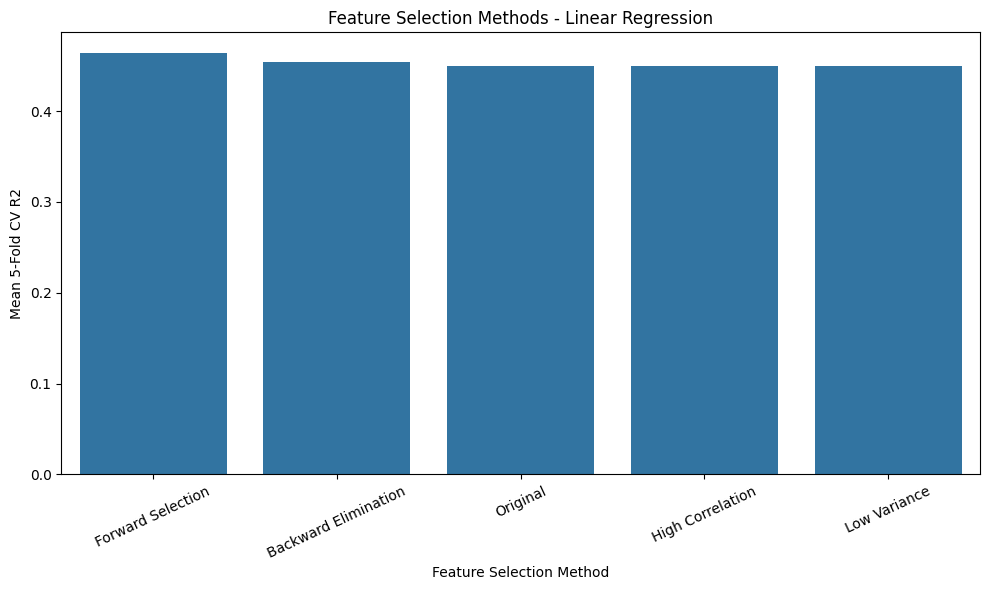

In [124]:
# 40-Compare cross-validation R2 scores for regression
plt.figure(figsize=(10, 6))

sns.barplot(
    data=reg_final_comparison,
    x="Method",
    y="CV Mean R2"
)

plt.title(
    "Feature Selection Methods - Linear Regression"
)

plt.xlabel("Feature Selection Method")
plt.ylabel("Mean 5-Fold CV R2")

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [125]:
# 41-Create a table showing how many features each regression method retained
reg_feature_counts = pd.DataFrame({
    "Method": list(reg_selected_sets.keys()),
    "Features Retained": [
        len(features)
        for features in reg_selected_sets.values()
    ]
})

# Create a table for classification
cls_feature_counts = pd.DataFrame({
    "Method": list(cls_selected_sets.keys()),
    "Features Retained": [
        len(features)
        for features in cls_selected_sets.values()
    ]
})


print("Regression Feature Counts")
display(reg_feature_counts)


print("Classification Feature Counts")
display(cls_feature_counts)

Regression Feature Counts


,Method,Features Retained
0,Original,10
1,Low Variance,10
2,High Correlation,10
3,Forward Selection,5
4,Backward Elimination,5


Classification Feature Counts


,Method,Features Retained
0,Original,30
1,Low Variance,14
2,High Correlation,20
3,Forward Selection,10
4,Backward Elimination,10


In [126]:
#42-
print("REGRESSION SELECTED FEATURES")

for method, features in reg_selected_sets.items():

    print("\n" + method)
    print(features)


print("\n" + "=" * 70)

print("\nCLASSIFICATION SELECTED FEATURES")

for method, features in cls_selected_sets.items():

    print("\n" + method)
    print(features)

REGRESSION SELECTED FEATURES

Original
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Low Variance
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

High Correlation
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Forward Selection
['sex', 'bmi', 'bp', 's3', 's5']

Backward Elimination
['sex', 'bmi', 'bp', 's1', 's5']


CLASSIFICATION SELECTED FEATURES

Original
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Low Vari

In [127]:
# 43-Test different numbers of selected features for Linear Regression
feature_numbers_reg = [
    3,
    5,
    7,
    9
]

# Store the results
self_learning_reg_results = []


for number in feature_numbers_reg:

    # Create a forward selection model with the current feature count
    selector = SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=number,
        direction="forward",
        scoring="r2",
        cv=5,
        n_jobs=-1
    )

    # Select the features using training data only
    selector.fit(
        X_reg_train_scaled,
        y_reg_train
    )

    # Get the selected feature names
    selected_features = X_reg_train_scaled.columns[
        selector.get_support()
    ].tolist()

    # Calculate 5-fold CV performance
    scores = cross_val_score(
        LinearRegression(),
        X_reg_train_scaled[selected_features],
        y_reg_train,
        cv=5,
        scoring="r2"
    )

    # Store the result
    self_learning_reg_results.append({
        "Features": number,
        "CV Mean R2": scores.mean(),
        "CV Std": scores.std(),
        "Selected Features": selected_features
    })


# Convert results to DataFrame
self_learning_reg_df = pd.DataFrame(
    self_learning_reg_results
)

print("Self-Learning Regression Experiment")

display(
    self_learning_reg_df[
        [
            "Features",
            "CV Mean R2",
            "CV Std"
        ]
    ]
)

Self-Learning Regression Experiment


,Features,CV Mean R2,CV Std
0,3,0.440058,0.105581
1,5,0.463556,0.127068
2,7,0.465774,0.132405
3,9,0.457147,0.134271


In [128]:
#44- Test different numbers of selected features for Logistic Regression
feature_numbers_cls = [
    5,
    10,
    15,
    20
]

# Store the classification results
self_learning_cls_results = []


for number in feature_numbers_cls:

    # Create a forward feature selector
    selector = SequentialFeatureSelector(
        LogisticRegression(
            max_iter=5000
        ),
        n_features_to_select=number,
        direction="forward",
        scoring="accuracy",
        cv=5,
        n_jobs=-1
    )

    # Perform feature selection
    selector.fit(
        X_cls_train_scaled,
        y_cls_train
    )

    # Get the selected feature names
    selected_features = X_cls_train_scaled.columns[
        selector.get_support()
    ].tolist()

    # Evaluate the selected features using 5-fold CV
    scores = cross_val_score(
        LogisticRegression(
            max_iter=5000
        ),
        X_cls_train_scaled[selected_features],
        y_cls_train,
        cv=5,
        scoring="accuracy"
    )

    # Store the result
    self_learning_cls_results.append({
        "Features": number,
        "CV Mean Accuracy": scores.mean(),
        "CV Std": scores.std(),
        "Selected Features": selected_features
    })


# Convert the results into a DataFrame
self_learning_cls_df = pd.DataFrame(
    self_learning_cls_results
)

print("Self-Learning Classification Experiment")

display(
    self_learning_cls_df[
        [
            "Features",
            "CV Mean Accuracy",
            "CV Std"
        ]
    ]
)

Self-Learning Classification Experiment


,Features,CV Mean Accuracy,CV Std
0,5,0.984615,0.011207
1,10,0.986813,0.010767
2,15,0.984615,0.011207
3,20,0.986813,0.010767


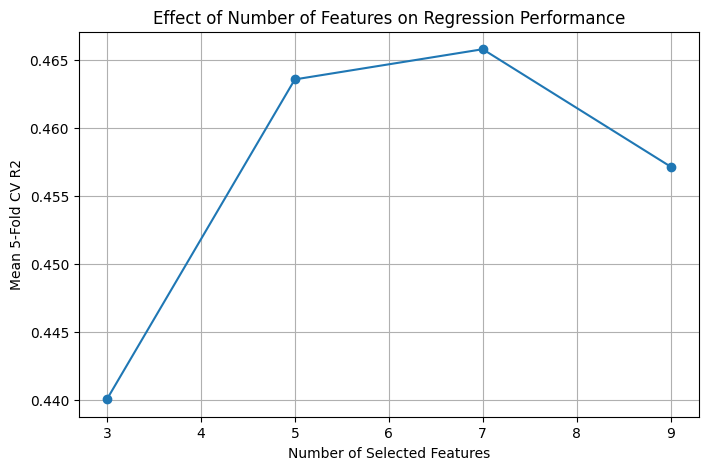

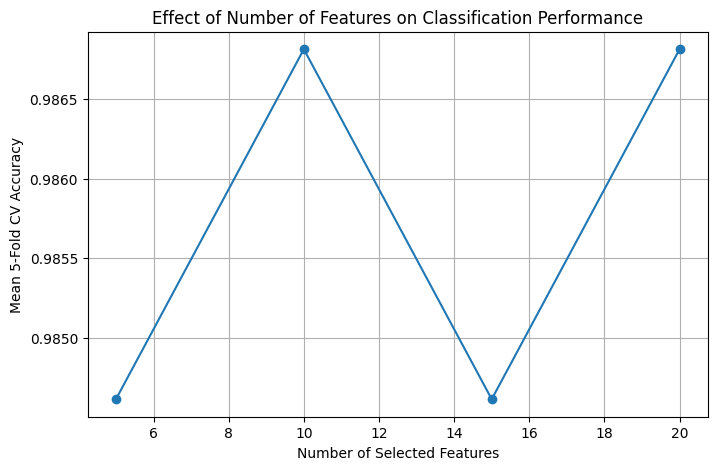

In [129]:
# 45-Plot how the number of features affects regression performance
plt.figure(figsize=(8, 5))

plt.plot(
    self_learning_reg_df["Features"],
    self_learning_reg_df["CV Mean R2"],
    marker="o"
)

plt.title(
    "Effect of Number of Features on Regression Performance"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Mean 5-Fold CV R2")

plt.grid(True)

plt.show()


# Plot classification performance
plt.figure(figsize=(8, 5))

plt.plot(
    self_learning_cls_df["Features"],
    self_learning_cls_df["CV Mean Accuracy"],
    marker="o"
)

plt.title(
    "Effect of Number of Features on Classification Performance"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Mean 5-Fold CV Accuracy")

plt.grid(True)

plt.show()

In [130]:
# 46-Find the regression method with the highest CV R2
best_regression = reg_final_comparison.loc[
    reg_final_comparison["CV Mean R2"].idxmax()
]

# Find the classification method with the highest CV accuracy
best_classification = cls_final_comparison.loc[
    cls_final_comparison["CV Mean Accuracy"].idxmax()
]


print("BEST LINEAR REGRESSION APPROACH")

print(
    "Method:",
    best_regression["Method"]
)

print(
    "Features:",
    best_regression["Features"]
)

print(
    "Test R2:",
    round(best_regression["R2"], 4)
)

print(
    "CV Mean R2:",
    round(best_regression["CV Mean R2"], 4)
)

print(
    "CV Std:",
    round(best_regression["CV Std"], 4)
)


print("\n" + "=" * 60)

print("\nBEST LOGISTIC REGRESSION APPROACH")

print(
    "Method:",
    best_classification["Method"]
)

print(
    "Features:",
    best_classification["Features"]
)

print(
    "Test Accuracy:",
    round(best_classification["Accuracy"], 4)
)

print(
    "CV Mean Accuracy:",
    round(
        best_classification["CV Mean Accuracy"],
        4
    )
)

print(
    "CV Std:",
    round(
        best_classification["CV Std"],
        4
    )
)

BEST LINEAR REGRESSION APPROACH
Method: Forward Selection
Features: 5
Test R2: 0.4694
CV Mean R2: 0.4636
CV Std: 0.1271


BEST LOGISTIC REGRESSION APPROACH
Method: Forward Selection
Features: 10
Test Accuracy: 0.9386
CV Mean Accuracy: 0.9868
CV Std: 0.0108


In [131]:
# 47-Compare the original feature set with the selected feature set

original_reg_r2 = reg_final_comparison.loc[
    reg_final_comparison["Method"] == "Original",
    "R2"
].iloc[0]

selected_reg_r2 = best_regression["R2"]

original_reg_rmse = reg_final_comparison.loc[
    reg_final_comparison["Method"] == "Original",
    "RMSE"
].iloc[0]

selected_reg_rmse = best_regression["RMSE"]

reg_r2_change = selected_reg_r2 - original_reg_r2
reg_rmse_change = selected_reg_rmse - original_reg_rmse


original_cls_accuracy = cls_final_comparison.loc[
    cls_final_comparison["Method"] == "Original",
    "Accuracy"
].iloc[0]

selected_cls_accuracy = best_classification["Accuracy"]

original_cls_f1 = cls_final_comparison.loc[
    cls_final_comparison["Method"] == "Original",
    "F1 Score"
].iloc[0]

selected_cls_f1 = best_classification["F1 Score"]

cls_accuracy_change = selected_cls_accuracy - original_cls_accuracy
cls_f1_change = selected_cls_f1 - original_cls_f1


self_learning_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression"
    ],
    "Original Performance": [
        original_reg_r2,
        original_cls_accuracy
    ],
    "Selected Performance": [
        selected_reg_r2,
        selected_cls_accuracy
    ],
    "Performance Change": [
        reg_r2_change,
        cls_accuracy_change
    ]
})

print("Original vs Selected Feature Performance")
display(self_learning_comparison)

print("\nRegression RMSE Comparison")
print("Original RMSE:", round(original_reg_rmse, 4))
print("Selected RMSE:", round(selected_reg_rmse, 4))
print("Change in RMSE:", round(reg_rmse_change, 4))

print("\nClassification F1 Comparison")
print("Original F1:", round(original_cls_f1, 4))
print("Selected F1:", round(selected_cls_f1, 4))
print("Change in F1:", round(cls_f1_change, 4))

Original vs Selected Feature Performance


,Model,Original Performance,Selected Performance,Performance Change
0,Linear Regression,0.452603,0.469365,0.016762
1,Logistic Regression,0.982456,0.938596,-0.043860



Regression RMSE Comparison
Original RMSE: 53.8534
Selected RMSE: 53.0225
Change in RMSE: -0.8309

Classification F1 Comparison
Original F1: 0.9861
Selected F1: 0.9504
Change in F1: -0.0358


In [132]:
# 48-Create a compact summary of the final regression comparison
final_regression_summary = reg_final_comparison[
    [
        "Method",
        "Features",
        "RMSE",
        "R2",
        "CV Mean R2",
        "CV Std"
    ]
].copy()


# Create a compact summary of the final classification comparison
final_classification_summary = cls_final_comparison[
    [
        "Method",
        "Features",
        "Accuracy",
        "F1 Score",
        "CV Mean Accuracy",
        "CV Std"
    ]
].copy()


print("FINAL REGRESSION SUMMARY")
display(final_regression_summary)


print("FINAL CLASSIFICATION SUMMARY")
display(final_classification_summary)

FINAL REGRESSION SUMMARY


,Method,Features,RMSE,R2,CV Mean R2,CV Std
3,Forward Selection,5,53.022496,0.469365,0.463556,0.127068
4,Backward Elimination,5,53.433595,0.461105,0.453939,0.113040
0,Original,10,53.853446,0.452603,0.449256,0.144095
2,High Correlation,10,53.853446,0.452603,0.449256,0.144095
1,Low Variance,10,53.853446,0.452603,0.449256,0.144095


FINAL CLASSIFICATION SUMMARY


,Method,Features,Accuracy,F1 Score,CV Mean Accuracy,CV Std
3,Forward Selection,10,0.938596,0.950355,0.986813,0.010767
4,Backward Elimination,10,0.973684,0.979021,0.984615,0.011207
0,Original,30,0.982456,0.986111,0.980220,0.012815
2,High Correlation,20,0.982456,0.986111,0.971429,0.020382
1,Low Variance,14,0.956140,0.965986,0.960440,0.011207


#49
# Final observations from the feature selection and model comparison experiments
# Feature selection reduced the number of input variables while maintaining model performance.
# Low Variance Filtering removed features with very little variation.
# High Correlation Filtering reduced redundant features.
# Forward Selection added useful features step by step.
# Backward Elimination started with all features and removed less useful features.
# Factor Analysis reduced the original variables into a smaller set of latent factors.
# Linear Regression was evaluated using MAE, MSE, RMSE and R2.
# Logistic Regression was evaluated using Accuracy, Precision, Recall and F1 Score.
# Five-fold cross-validation was used to compare mean performance and variation using standard deviation.
# Gradient Descent was used to study the effect of learning rate and number of iterations on convergence.
# GridSearchCV was used to identify a suitable C value for Logistic Regression.
# The self-learning experiment tested different numbers of selected features to improve validation performance.